# Statistical Analysis - Performance Testing

This notebook will show an insight into the performance testing that was done on my statistical analysis program showing how changing metrics on the cluster can cause interesting differences to do with factors like runtime and throughput.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Executor Scaling

In [15]:
executors = pd.read_excel("FYP_final_performance_tracker.xlsx", "StatAnalysis - Executors")
executors[["num_executors", "total_cores", "runtime_seconds"]]

,num_executors,total_cores,runtime_seconds
0,2,8,1206.754
1,4,16,983.591
2,6,24,567.461
3,8,32,392.952
4,10,40,356.849


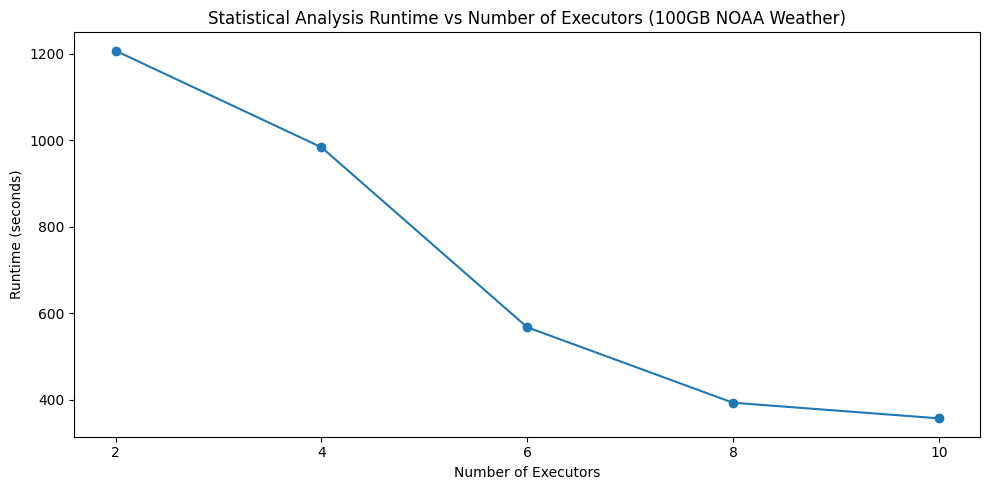

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(executors["num_executors"],
         executors["runtime_seconds"],
         marker="o")

plt.title("Statistical Analysis Runtime vs Number of Executors (100GB NOAA Weather)")
plt.xlabel("Number of Executors")
plt.ylabel("Runtime (seconds)")
plt.xticks(executors["num_executors"])

plt.tight_layout()
plt.show()

## Break Down of Results - executors (runtime):

### Strong runtime improvement:
- runtime drops from around 1207s all the way to around 357s
- each of the additions improves the runtime

### Biggest improvement:
- largest drop in runtime seen from 4 executors to 6 executors

### Gains continue but seem to level off:
- 8 to 10 executors runtime seems to start decreasing in momentum

### Relative Speedup - Executors

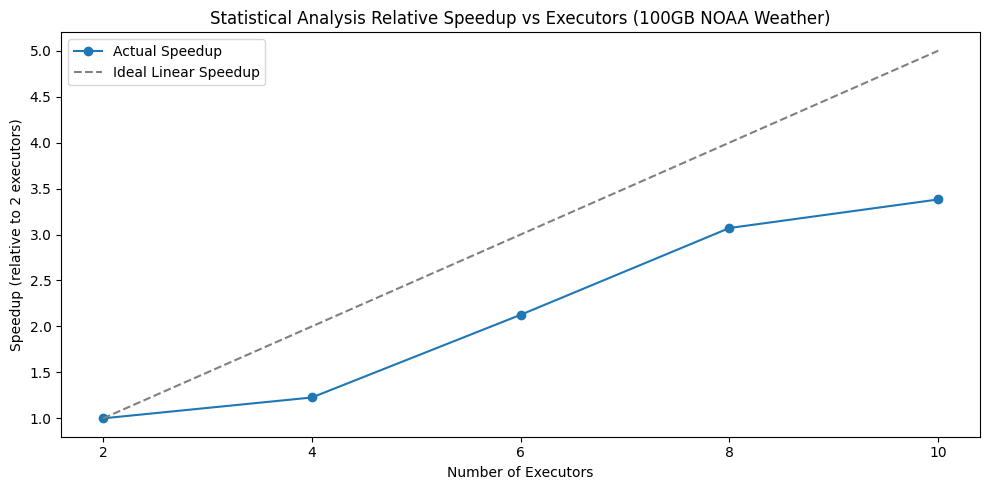

In [14]:
baseline_runtime = executors.iloc[0]["runtime_seconds"] 

plt.figure(figsize=(10, 5))

speedup = baseline_runtime / executors["runtime_seconds"]
ideal = executors["num_executors"] / executors["num_executors"].iloc[0]

plt.plot(executors["num_executors"], speedup, marker="o", label="Actual Speedup")
plt.plot(executors["num_executors"], ideal, linestyle="--", color="gray", label="Ideal Linear Speedup")

plt.title("Statistical Analysis Relative Speedup vs Executors (100GB NOAA Weather)")
plt.xlabel("Number of Executors")
plt.ylabel("Speedup (relative to 2 executors)")
plt.xticks(executors["num_executors"])
plt.legend()

plt.tight_layout()
plt.show()

## Break Down of Results - relative speedup

### Actual speedup improves with more executors
- Speedup increase from the baseline 1x to 3.3x for 10 executors

### The gap shows that scaling is not completely linear
- Performance improves quite a bit but not proportionally due to factors like the cluster usage and network latency

## Partition Scaling

In [16]:
partitions = pd.read_excel("FYP_final_performance_tracker.xlsx", "StatAnalysis - Partitions")
partitions[["shuffle_partitions", "runtime_seconds"]]

,shuffle_partitions,runtime_seconds
0,16,970.285
1,32,991.799
2,64,967.641
3,128,883.676
4,200,998.173
5,400,626.861
6,400,1130.233
7,400,1108.671
8,800,1133.825


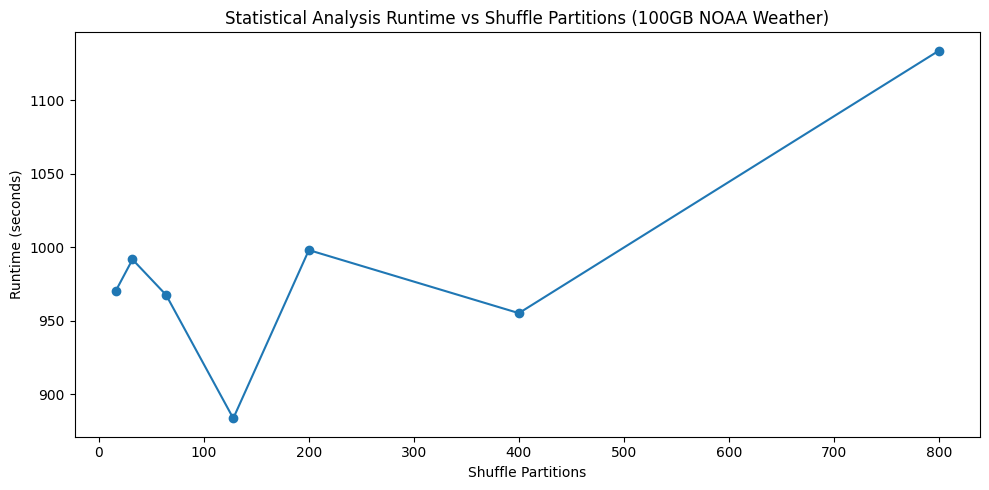

In [7]:
# For repeated partition values (400 has 3 runs), use mean
part_avg = partitions.groupby("shuffle_partitions")["runtime_seconds"].mean().reset_index()

plt.figure(figsize=(10, 5))

plt.plot(part_avg["shuffle_partitions"],
         part_avg["runtime_seconds"],
         marker="o")

plt.title("Statistical Analysis Runtime vs Shuffle Partitions (100GB NOAA Weather)")
plt.xlabel("Shuffle Partitions")
plt.ylabel("Runtime (seconds)")

plt.tight_layout()
plt.show()

## Break Down of Results - partitions

### Runtime varies across shuffle partition values:
- the runtime does not follow a smooth increase or decrease
- the results seem to be in the range of around 850s to 1150s showing the runtime range can change quite a bit when changing the partition size

### Lowest runtime observed:
- 128 partitions seemed to provide the most efficient course of speeding up the runtime



In [11]:
import pandas as pd

executors = pd.read_excel(
    "FYP_final_performance_tracker.xlsx",
    sheet_name="StatAnalysis - Executors"
)

executors[["num_executors", "total_cores", "runtime_seconds", "throughput_mbps"]]


,num_executors,total_cores,runtime_seconds,throughput_mbps
0,2,8,1206.754,86.67
1,4,16,983.591,106.33
2,6,24,567.461,184.31
3,8,32,392.952,266.16
4,10,40,356.849,293.09


## Throughput Speedup - Executors

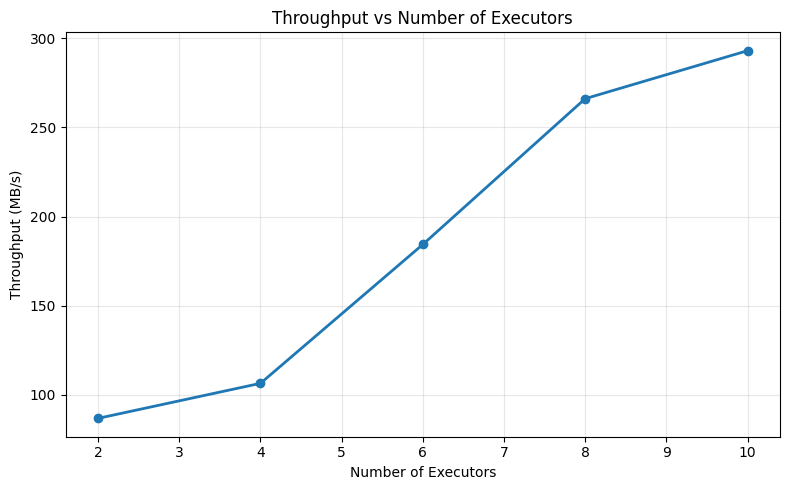

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    executors["num_executors"],
    executors["throughput_mbps"],
    marker="o",
    linestyle="-",
    linewidth=2
)

plt.xlabel("Number of Executors")
plt.ylabel("Throughput (MB/s)")
plt.title("Throughput vs Number of Executors")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Break Down of Results - executors (throughput):

### Throughput rises as more executors are added:
- Throughput increases from around 90MB/s all the way to just below 300MB/s

### Largest jump in performance:
- The increase is clear from 4 to 6 executors that the performance is alot better

### Slowing performance:
- From 8 to 10 executors the performance increase is not as big which could be showing that the limits are being reached in terms of bandwidth

